In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Final Model Selection and Test Evaluation

## Final Model Selection

The Decision Tree Classifier was selected as the final model before evaluating the reserved test dataset.

During three fold stratified cross validation, the Decision Tree achieved approximately:

`Accuracy = 0.99994`

`Macro F1 = 0.99985`

It slightly outperformed the Random Forest in Macro F1 while also showing slightly lower variation across the validation folds.

The Decision Tree is also simpler and more interpretable than the Random Forest.

The exploratory analysis showed that the target variable follows simple threshold based relationships involving Production Speed and Error Rate. A Decision Tree is naturally suited to representing this type of relationship.

The final model was therefore selected based on development and cross validation results rather than final test performance.

In [ ]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "manufacturing_6G_dataset.csv"
)

figures_dir = project_root / "figures"
figures_dir.mkdir(exist_ok=True)

results_dir = project_root / "results"
results_dir.mkdir(exist_ok=True)

df = pd.read_csv(dataset_path)

df["Timestamp"] = pd.to_datetime(
    df["Timestamp"]
)

print("Dataset shape:", df.shape)

Dataset shape: (100000, 13)


In [ ]:
X = df.drop(
    columns=[
        "Efficiency_Status",
        "Timestamp",
        "Machine_ID"
    ]
)

y = df["Efficiency_Status"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 10)
y shape: (100000,)


In [ ]:
X_development, X_test, y_development, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)

print(
    "Final development set:",
    X_development.shape
)

print(
    "Final test set:",
    X_test.shape
)

Final development set: (80000, 10)
Final test set: (20000, 10)


In [ ]:
test_distribution = (
    y_test
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(
    test_distribution
)

Efficiency_Status
Low       77.82
Medium    19.19
High       2.99
Name: proportion, dtype: float64


In [ ]:
numerical_features = [
    "Temperature_C",
    "Vibration_Hz",
    "Power_Consumption_kW",
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Quality_Control_Defect_Rate_%",
    "Production_Speed_units_per_hr",
    "Predictive_Maintenance_Score",
    "Error_Rate_%"
]

categorical_features = [
    "Operation_Mode"
]

class_order = [
    "Low",
    "Medium",
    "High"
]

In [ ]:
final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            "passthrough",
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [ ]:
final_pipeline = Pipeline(
    steps=[
        (
            "preprocessing",
            final_preprocessor
        ),
        (
            "model",
            DecisionTreeClassifier(
                random_state=42
            )
        )
    ]
)

final_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, de

In [ ]:
final_pipeline.fit(
    X_development,
    y_development
)

print(
    "Final Decision Tree trained "
    "using the complete development set."
)

Final Decision Tree trained using the complete development set.


In [ ]:
final_tree = (
    final_pipeline
    .named_steps["model"]
)

print(
    "Final tree depth:",
    final_tree.get_depth()
)

print(
    "Final number of leaves:",
    final_tree.get_n_leaves()
)

Final tree depth: 4
Final number of leaves: 5


In [ ]:
final_predictions = (
    final_pipeline.predict(
        X_test
    )
)

print(
    "Final test predictions generated."
)

Final test predictions generated.


In [ ]:
final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_macro_precision = precision_score(
    y_test,
    final_predictions,
    average="macro",
    zero_division=0
)

final_macro_recall = recall_score(
    y_test,
    final_predictions,
    average="macro",
    zero_division=0
)

final_macro_f1 = f1_score(
    y_test,
    final_predictions,
    average="macro",
    zero_division=0
)

final_weighted_f1 = f1_score(
    y_test,
    final_predictions,
    average="weighted",
    zero_division=0
)

print(
    "Final Test Accuracy:",
    round(final_accuracy, 6)
)

print(
    "Final Macro Precision:",
    round(final_macro_precision, 6)
)

print(
    "Final Macro Recall:",
    round(final_macro_recall, 6)
)

print(
    "Final Macro F1:",
    round(final_macro_f1, 6)
)

print(
    "Final Weighted F1:",
    round(final_weighted_f1, 6)
)

Final Test Accuracy: 0.99985
Final Macro Precision: 0.99987
Final Macro Recall: 0.999268
Final Macro F1: 0.999569
Final Weighted F1: 0.99985


In [ ]:
correct_predictions = (
    final_predictions
    == y_test.to_numpy()
)

number_correct = (
    correct_predictions.sum()
)

number_errors = (
    len(y_test)
    -
    number_correct
)

print(
    "Test observations:",
    len(y_test)
)

print(
    "Correct predictions:",
    number_correct
)

print(
    "Incorrect predictions:",
    number_errors
)

Test observations: 20000
Correct predictions: 19997
Incorrect predictions: 3


In [ ]:
print(
    classification_report(
        y_test,
        final_predictions,
        labels=class_order,
        zero_division=0,
        digits=4
    )
)

              precision    recall  f1-score   support

         Low     0.9999    1.0000    0.9999     15565
      Medium     0.9997    0.9995    0.9996      3838
        High     1.0000    0.9983    0.9992       597

    accuracy                         0.9999     20000
   macro avg     0.9999    0.9993    0.9996     20000
weighted avg     0.9998    0.9999    0.9998     20000



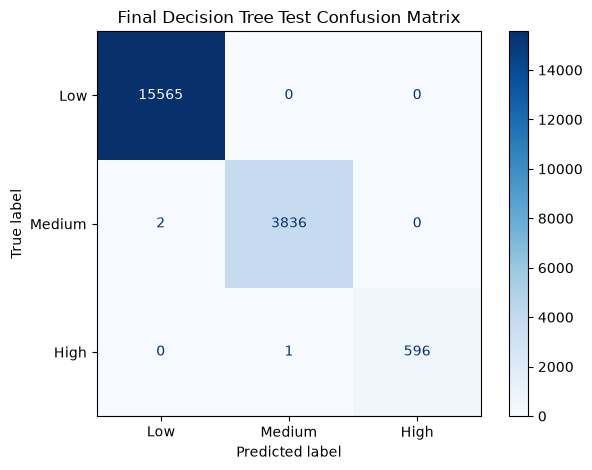

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    final_predictions,
    labels=class_order,
    cmap="Blues",
    values_format="d"
)

plt.title(
    "Final Decision Tree Test Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    figures_dir
    / "final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
final_metrics = pd.DataFrame([
    {
        "Model":
            "Decision Tree",

        "Accuracy":
            final_accuracy,

        "Macro Precision":
            final_macro_precision,

        "Macro Recall":
            final_macro_recall,

        "Macro F1":
            final_macro_f1,

        "Weighted F1":
            final_weighted_f1,

        "Test Errors":
            number_errors
    }
])

final_metrics.round(6)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Test Errors
0,Decision Tree,0.99985,0.99987,0.999268,0.999569,0.99985,3


In [ ]:
final_metrics.to_csv(
    results_dir
    / "final_test_metrics.csv",
    index=False
)

print(
    "Final metrics saved."
)

Final metrics saved.


In [ ]:
comparison = pd.DataFrame([
    {
        "Evaluation":
            "notebook 4 Cross Validation",

        "Accuracy":
            0.99994,

        "Macro F1":
            0.99985
    },
    {
        "Evaluation":
            "Final Test",

        "Accuracy":
            final_accuracy,

        "Macro F1":
            final_macro_f1
    }
])

comparison.round(6)

,Evaluation,Accuracy,Macro F1
0,notebook 4 Cross Validation,0.99994,0.999850
1,Final Test,0.99985,0.999569


In [ ]:
error_analysis = (
    X_test.copy()
)

error_analysis[
    "Actual"
] = y_test

error_analysis[
    "Predicted"
] = final_predictions

misclassified = (
    error_analysis[
        error_analysis["Actual"]
        !=
        error_analysis["Predicted"]
    ]
)

print(
    "Misclassified observations:",
    len(misclassified)
)

misclassified.head(20)

Misclassified observations: 3


,Operation_Mode,Temperature_C,Vibration_Hz,Power_Consumption_kW,Network_Latency_ms,Packet_Loss_%,Quality_Control_Defect_Rate_%,Production_Speed_units_per_hr,Predictive_Maintenance_Score,Error_Rate_%,Actual,Predicted
93879,Idle,89.472039,4.249606,7.596787,2.677094,2.717082,8.560009,255.024919,0.354739,4.999888,Medium,Low
50839,Active,53.531553,4.623593,9.901066,23.212233,3.701541,0.808779,400.122161,0.758590,1.407925,High,Medium
53754,Active,59.030803,3.484706,6.397685,40.082969,4.175265,6.535793,382.860869,0.470211,4.999847,Medium,Low


In [ ]:
misclassified[
    [
        "Production_Speed_units_per_hr",
        "Error_Rate_%",
        "Operation_Mode",
        "Actual",
        "Predicted"
    ]
]

,Production_Speed_units_per_hr,Error_Rate_%,Operation_Mode,Actual,Predicted
93879,255.024919,4.999888,Idle,Medium,Low
50839,400.122161,1.407925,Active,High,Medium
53754,382.860869,4.999847,Active,Medium,Low


In [ ]:
error_types = (
    pd.crosstab(
        misclassified["Actual"],
        misclassified["Predicted"]
    )
)

error_types

Predicted,Low,Medium
Actual,,
High,0,1
Medium,2,0


In [ ]:
sample_data = (
    X_test.iloc[:5]
)

sample_predictions = (
    final_pipeline.predict(
        sample_data
    )
)

sample_results = pd.DataFrame({
    "Actual":
        y_test.iloc[:5].values,

    "Predicted":
        sample_predictions
})

sample_results

,Actual,Predicted
0,Low,Low
1,Low,Low
2,Low,Low
3,Low,Low
4,Low,Low


In [ ]:
from sklearn.tree import export_text

feature_names = (
    final_pipeline
    .named_steps["preprocessing"]
    .get_feature_names_out()
)

tree_rules = export_text(
    final_tree,
    feature_names=list(feature_names),
    decimals=4
)

print(tree_rules)

|--- numerical__Error_Rate_% <= 4.9998
|   |--- numerical__Production_Speed_units_per_hr <= 199.9958
|   |   |--- class: Low
|   |--- numerical__Production_Speed_units_per_hr >  199.9958
|   |   |--- numerical__Production_Speed_units_per_hr <= 400.1699
|   |   |   |--- class: Medium
|   |   |--- numerical__Production_Speed_units_per_hr >  400.1699
|   |   |   |--- numerical__Error_Rate_% <= 2.0006
|   |   |   |   |--- class: High
|   |   |   |--- numerical__Error_Rate_% >  2.0006
|   |   |   |   |--- class: Medium
|--- numerical__Error_Rate_% >  4.9998
|   |--- class: Low



# Final Model Evaluation

## Final Model Selection

The Decision Tree Classifier was selected as the final model before accessing the reserved test dataset.

During three fold stratified cross validation, the Decision Tree achieved approximately:

`Cross Validation Accuracy = 0.99994`

`Cross Validation Macro F1 = 0.99985`

It slightly outperformed the Random Forest according to Macro F1 while also showing slightly lower variation across the validation folds.

The Decision Tree was also selected because it provides a simpler and more interpretable representation of the threshold based target structure identified during exploratory analysis.

## Final Training

After model selection was completed, the previously separated training and validation portions were recombined.

The final Decision Tree pipeline was trained using all `80,000` development observations.

The remaining `20,000` observations were kept separate for final evaluation.

The final trained tree had:

`Tree Depth = 4`

`Number of Leaves = 5`

This relatively small tree is consistent with the simple threshold based target structure identified during the earlier analysis.

## Final Test Evaluation

The final Decision Tree was evaluated once on the reserved test dataset.

The final results were:

`Accuracy = 0.999850`

`Macro Precision = 0.999870`

`Macro Recall = 0.999268`

`Macro F1 = 0.999569`

`Weighted F1 = 0.999850`

The classifier correctly predicted `19,997` of the `20,000` unseen test observations and made only `3` classification errors.

## Class Specific Performance

The final model achieved strong performance across all three efficiency classes.

The High efficiency class, despite representing only approximately 3% of the dataset, achieved:

`Precision = 1.0000`

`Recall = 0.9983`

`F1 = 0.9992`

This confirms that the high overall accuracy was not produced simply by favouring the majority Low class.

## Error Analysis

The three final test errors consisted of:

`2 Medium observations classified as Low`

`1 High observation classified as Medium`

The misclassified observations were located extremely close to the previously identified decision boundaries.

Two Medium observations had Error Rate values of approximately:

`4.999888`

`4.999847`

which are extremely close to the observed threshold of `5`.

The incorrectly classified High observation had a Production Speed of approximately:

`400.122`

which is very close to the observed High efficiency threshold of `400`.

This suggests that the remaining prediction errors occur near the learned decision boundaries.

## Comparison With Cross Validation

The Day 4 Decision Tree cross validation accuracy was approximately:

`0.99994`

while the final test accuracy was:

`0.99985`

The cross validation Macro F1 was approximately:

`0.99985`

while the final test Macro F1 was:

`0.999569`

The differences are very small, indicating that the final test performance is consistent with the performance estimated during cross validation.

No model parameters or input features were modified after observing the final test results.

## Interpretation

The very strong Decision Tree performance should be interpreted together with the exploratory and ablation analyses.

The supplied `Efficiency_Status` target follows simple threshold based relationships involving:

`Production_Speed_units_per_hr`

`Error_Rate_%`

Notebook 5 showed that these two variables accounted for approximately `98.17%` of the Random Forest impurity based feature importance.

Removing them reduced Random Forest Macro F1 from approximately `0.9997` to `0.2920`, which was approximately equivalent to the majority class baseline.

Therefore, the very high final test performance is primarily explained by the structure of the supplied target variable rather than by complex predictive relationships across all available manufacturing variables.

## Final Project Conclusion

This project investigated multiclass manufacturing efficiency classification using a Majority Baseline, SGD Classifier, Decision Tree Classifier, and Random Forest Classifier.

Because the target classes were strongly imbalanced, model evaluation included Macro Precision, Macro Recall, Macro F1, class specific metrics, and confusion matrices in addition to accuracy.

The Decision Tree achieved the strongest cross validation performance and was selected as the final model.

On the untouched final test dataset, it achieved approximately `99.985%` accuracy and `0.999569` Macro F1, with only three incorrect predictions among 20,000 observations.

Exploratory analysis, deterministic rule verification, feature importance, and feature ablation consistently showed that Production Speed and Error Rate contain the dominant predictive information for the provided Efficiency Status labels.

The project demonstrates that high predictive performance should not be interpreted in isolation. Understanding target construction, feature relationships, class imbalance, and model behaviour is essential for correctly evaluating machine learning systems.